In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


file_path = 'CICIDS/Dataset.csv'

# Load the dataset
df = pd.read_csv(file_path)
df


,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,192.168.0.22,8.8.8.8,49547,53,17,1/20/2026,10:53,40264.0,1,1,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,DNS
1,192.168.0.22,8.8.8.8,33536,53,17,1/20/2026,10:53,48602.0,1,1,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,DNS
2,192.168.0.22,8.8.8.8,39600,53,17,1/20/2026,10:53,38258.0,1,1,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,DNS
3,192.168.0.22,8.8.8.8,58225,53,17,1/20/2026,10:53,38665.0,1,1,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,DNS
4,192.168.0.22,8.8.8.8,58643,53,17,1/20/2026,10:53,50153.0,1,1,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,DNS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249716,169.254.54.29,169.254.255.255,137,137,17,14/08/2021,01:03:21,1503284.0,3,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,other
249717,169.254.54.29,169.254.255.255,137,137,17,14/08/2021,01:31:30,1499853.0,3,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,other
249718,169.254.54.29,169.254.255.255,137,137,17,14/08/2021,11:15:55,1501466.0,3,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,other
249719,169.254.54.29,169.254.255.255,137,137,17,14/08/2021,09:57:24,1499963.0,3,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,other


In [2]:
# Count how many times each (label, label.1) pair appears
subcategory_counts = df.groupby(['Label']).size().reset_index(name='count')
print(subcategory_counts)


   Label  count
0    DNS  61241
1    FTP  47250
2  HTTPS  25384
3    SSH  48657
4    VPN  56644
5  other  10545


In [3]:
# rename CWR flag count -> CWE flag count
#df = df.rename(columns={"CWR Flag Count": "CWE Flag Count"})

In [4]:
# df = df[df['Label'] != 'VPN']

In [5]:
#df = df.drop(['Src IP', 'Src Port', 'Dst IP', 'Dst Port','Timestamp','Protocol'], axis=1)   # X is all columns except the label



In [6]:
df = df.drop(['src_ip','dst_ip','src_port','dst_port','protocol','timestamp','flow_duration'], axis=1)   # X is all columns except the label

In [7]:
merged_df=df

In [8]:

# # Merge the datasets row-wise
# merged_df = pd.concat([df,df1], ignore_index=True)

# # Drop rows with any missing values from the merged dataset
# merged_df.dropna(inplace=True)

# # Save the cleaned, merged DataFrame
# modified_path = 'ETA.csv'
# merged_df.to_csv(modified_path, index=False)

# # Display the first few rows (optional)
# print(merged_df.head())

In [9]:
# Get unique label classes
label_classes = merged_df['Label'].unique()
print("Label Classes:", label_classes)


Label Classes: ['DNS' 'FTP' 'SSH' 'other' 'VPN' 'HTTPS']


In [10]:
# Count how many times each (label, label.1) pair appears
subcategory_counts = merged_df.groupby(['Label']).size().reset_index(name='count')
print(subcategory_counts)

   Label  count
0    DNS  61241
1    FTP  47250
2  HTTPS  25384
3    SSH  48657
4    VPN  56644
5  other  10545


In [11]:
# merged_df = merged_balanced

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
merged_df['Label']= label_encoder.fit_transform(merged_df['Label'])
merged_df

,flow_byts_s,flow_pkts_s,fwd_pkts_s,bwd_pkts_s,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,fwd_pkt_len_min,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,40264.0,1,1,70,86,70,70,70.0,0.0,86,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,0
1,48602.0,1,1,70,86,70,70,70.0,0.0,86,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,0
2,38258.0,1,1,70,86,70,70,70.0,0.0,86,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,0
3,38665.0,1,1,70,86,70,70,70.0,0.0,86,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,0
4,50153.0,1,1,70,86,70,70,70.0,0.0,86,...,1,8,0.0,0.0,0,0,0.000000e+00,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249716,1503284.0,3,0,150,0,50,50,50.0,0.0,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,5
249717,1499853.0,3,0,150,0,50,50,50.0,0.0,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,5
249718,1501466.0,3,0,150,0,50,50,50.0,0.0,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,5
249719,1499963.0,3,0,150,0,50,50,50.0,0.0,0,...,2,8,0.0,0.0,0,0,1.630000e+15,0.0,1630000000000000,5


In [12]:
import pickle

with open('ETA_labelencoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

In [13]:
# Get unique label classes
label_classes = merged_df['Label'].unique()
print("Label Classes:", label_classes)

Label Classes: [0 1 3 5 4 2]


In [14]:
from sklearn.preprocessing import StandardScaler

# Columns to exclude from scaling
non_numeric_cols = ['Label']

# Select only numeric columns from merged_df
numeric_cols = merged_df.select_dtypes(include=['int64', 'float64']).columns
cols_to_scale = [col for col in numeric_cols if col not in non_numeric_cols]

# Replace infinite values with NaN
merged_df[cols_to_scale] = merged_df[cols_to_scale].replace([np.inf, -np.inf], np.nan)

# We will fit the scaler later on the selected features.
# For now, just show the head without scaling.
print(merged_df.head())

   flow_byts_s  flow_pkts_s  fwd_pkts_s  bwd_pkts_s  tot_fwd_pkts  \
0      40264.0            1           1          70            86   
1      48602.0            1           1          70            86   
2      38258.0            1           1          70            86   
3      38665.0            1           1          70            86   
4      50153.0            1           1          70            86   

   tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  fwd_pkt_len_max  \
0            70               70             70.0              0.0   
1            70               70             70.0              0.0   
2            70               70             70.0              0.0   
3            70               70             70.0              0.0   
4            70               70             70.0              0.0   

   fwd_pkt_len_min  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0               86  ...                 1                 8               0.0   
1 

In [15]:
COLUMN_MAPPING = {
    "Flow Duration":"flow_duration",
    "Total Fwd Packet": "tot_fwd_pkts",
    "Total Bwd packets": "tot_bwd_pkts",
    "Total Length of Fwd Packet": "totlen_fwd_pkts",
    "Total Length of Bwd Packet": "totlen_bwd_pkts",
    "Fwd Packet Length Max": "fwd_pkt_len_max",
    "Fwd Packet Length Min": "fwd_pkt_len_min",
    "Fwd Packet Length Mean": "fwd_pkt_len_mean",
    "Fwd Packet Length Std": "fwd_pkt_len_std",
    "Bwd Packet Length Max": "bwd_pkt_len_max",
    "Bwd Packet Length Min": "bwd_pkt_len_min",
    "Bwd Packet Length Mean": "bwd_pkt_len_mean",
    "Bwd Packet Length Std": "bwd_pkt_len_std",
    "Flow Bytes/s": "flow_byts_s",
    "Flow Packets/s": "flow_pkts_s",
    "Flow IAT Mean": "flow_iat_mean", 
    "Flow IAT Std":  "flow_iat_std", 
    "Flow IAT Max": "flow_iat_max",
    "Flow IAT Min":"flow_iat_min",
    "Fwd IAT Total": "fwd_iat_total",
    "Fwd IAT Mean": "fwd_iat_mean",
    "Fwd IAT Std": "fwd_iat_std",
    "Fwd IAT Max": "fwd_iat_max",
    "Fwd IAT Min": "fwd_iat_min",
    "Bwd IAT Total": "bwd_iat_total",
    "Bwd IAT Mean": "bwd_iat_mean",
    "Bwd IAT Std": "bwd_iat_std",
    "Bwd IAT Max": "bwd_iat_max", 
    "Bwd IAT Min": "bwd_iat_min", 
    "Fwd PSH Flags": "fwd_psh_flags",
    "Bwd PSH Flags": "bwd_psh_flags", 
    "Fwd URG Flags": "fwd_urg_flags", 
    "Bwd URG Flags": "bwd_urg_flags", 
    "Fwd Header Length": "fwd_header_len",
    "Bwd Header Length": "bwd_header_len",
    "Fwd Packets/s": "fwd_pkts_s",
    "Bwd Packets/s": "bwd_pkts_s",
    "Packet Length Max": "pkt_len_max",
    "Packet Length Min": "pkt_len_min",
    "Packet Length Mean": "pkt_len_mean",
    "Packet Length Std": "pkt_len_std",
    "Packet Length Variance": "pkt_len_var",
    "FIN Flag Count": "fin_flag_cnt",
    "SYN Flag Count": "syn_flag_cnt",
    "RST Flag Count": "rst_flag_cnt",
    "PSH Flag Count": "psh_flag_cnt",
    "ACK Flag Count": "ack_flag_cnt",
    "URG Flag Count": "urg_flag_cnt",
    "CWE Flag Count": "cwe_flag_cnt",
    "ECE Flag Count": "ece_flag_cnt",
    "Down/Up Ratio": "down_up_ratio",
    "Average Packet Size": "pkt_size_avg" ,
    "Fwd Segment Size Avg": "fwd_seg_size_avg", 
    "Bwd Segment Size Avg": "bwd_seg_size_avg",
    "Fwd Bytes/Bulk Avg": "fwd_byts_b_avg",
    "Fwd Packet/Bulk Avg": "fwd_pkts_b_avg",
    "Fwd Bulk Rate Avg": "fwd_blk_rate_avg",
    "Bwd Bytes/Bulk Avg": "bwd_byts_b_avg",
    "Bwd Packet/Bulk Avg": "bwd_pkts_b_avg",
    "Bwd Bulk Rate Avg": "bwd_blk_rate_avg",
    "Subflow Fwd Packets": "subflow_fwd_pkts",
    "Subflow Fwd Bytes": "subflow_fwd_byts",
    "Subflow Bwd Packets": "subflow_bwd_pkts",
    "Subflow Bwd Bytes": "subflow_bwd_byts",
    "FWD Init Win Bytes": "init_fwd_win_byts",
    "Bwd Init Win Bytes": "init_bwd_win_byts",
    "Fwd Act Data Pkts": "fwd_act_data_pkts",
    "Fwd Seg Size Min": "fwd_seg_size_min",
    "Active Mean": "active_mean",
    "Active Std": "active_std",
    "Active Max": "active_max",
    "Active Min": "active_min",
    "Idle Mean": "idle_mean",
    "Idle Std": "idle_std",
    "Idle Max": "idle_max",
    "Idle Min": "idle_min"
}


In [16]:
# Find duplicated column names
duplicate_columns = merged_df.columns[merged_df.columns.duplicated()].tolist()

print("Duplicate columns found:")
print(duplicate_columns)


Duplicate columns found:
[]


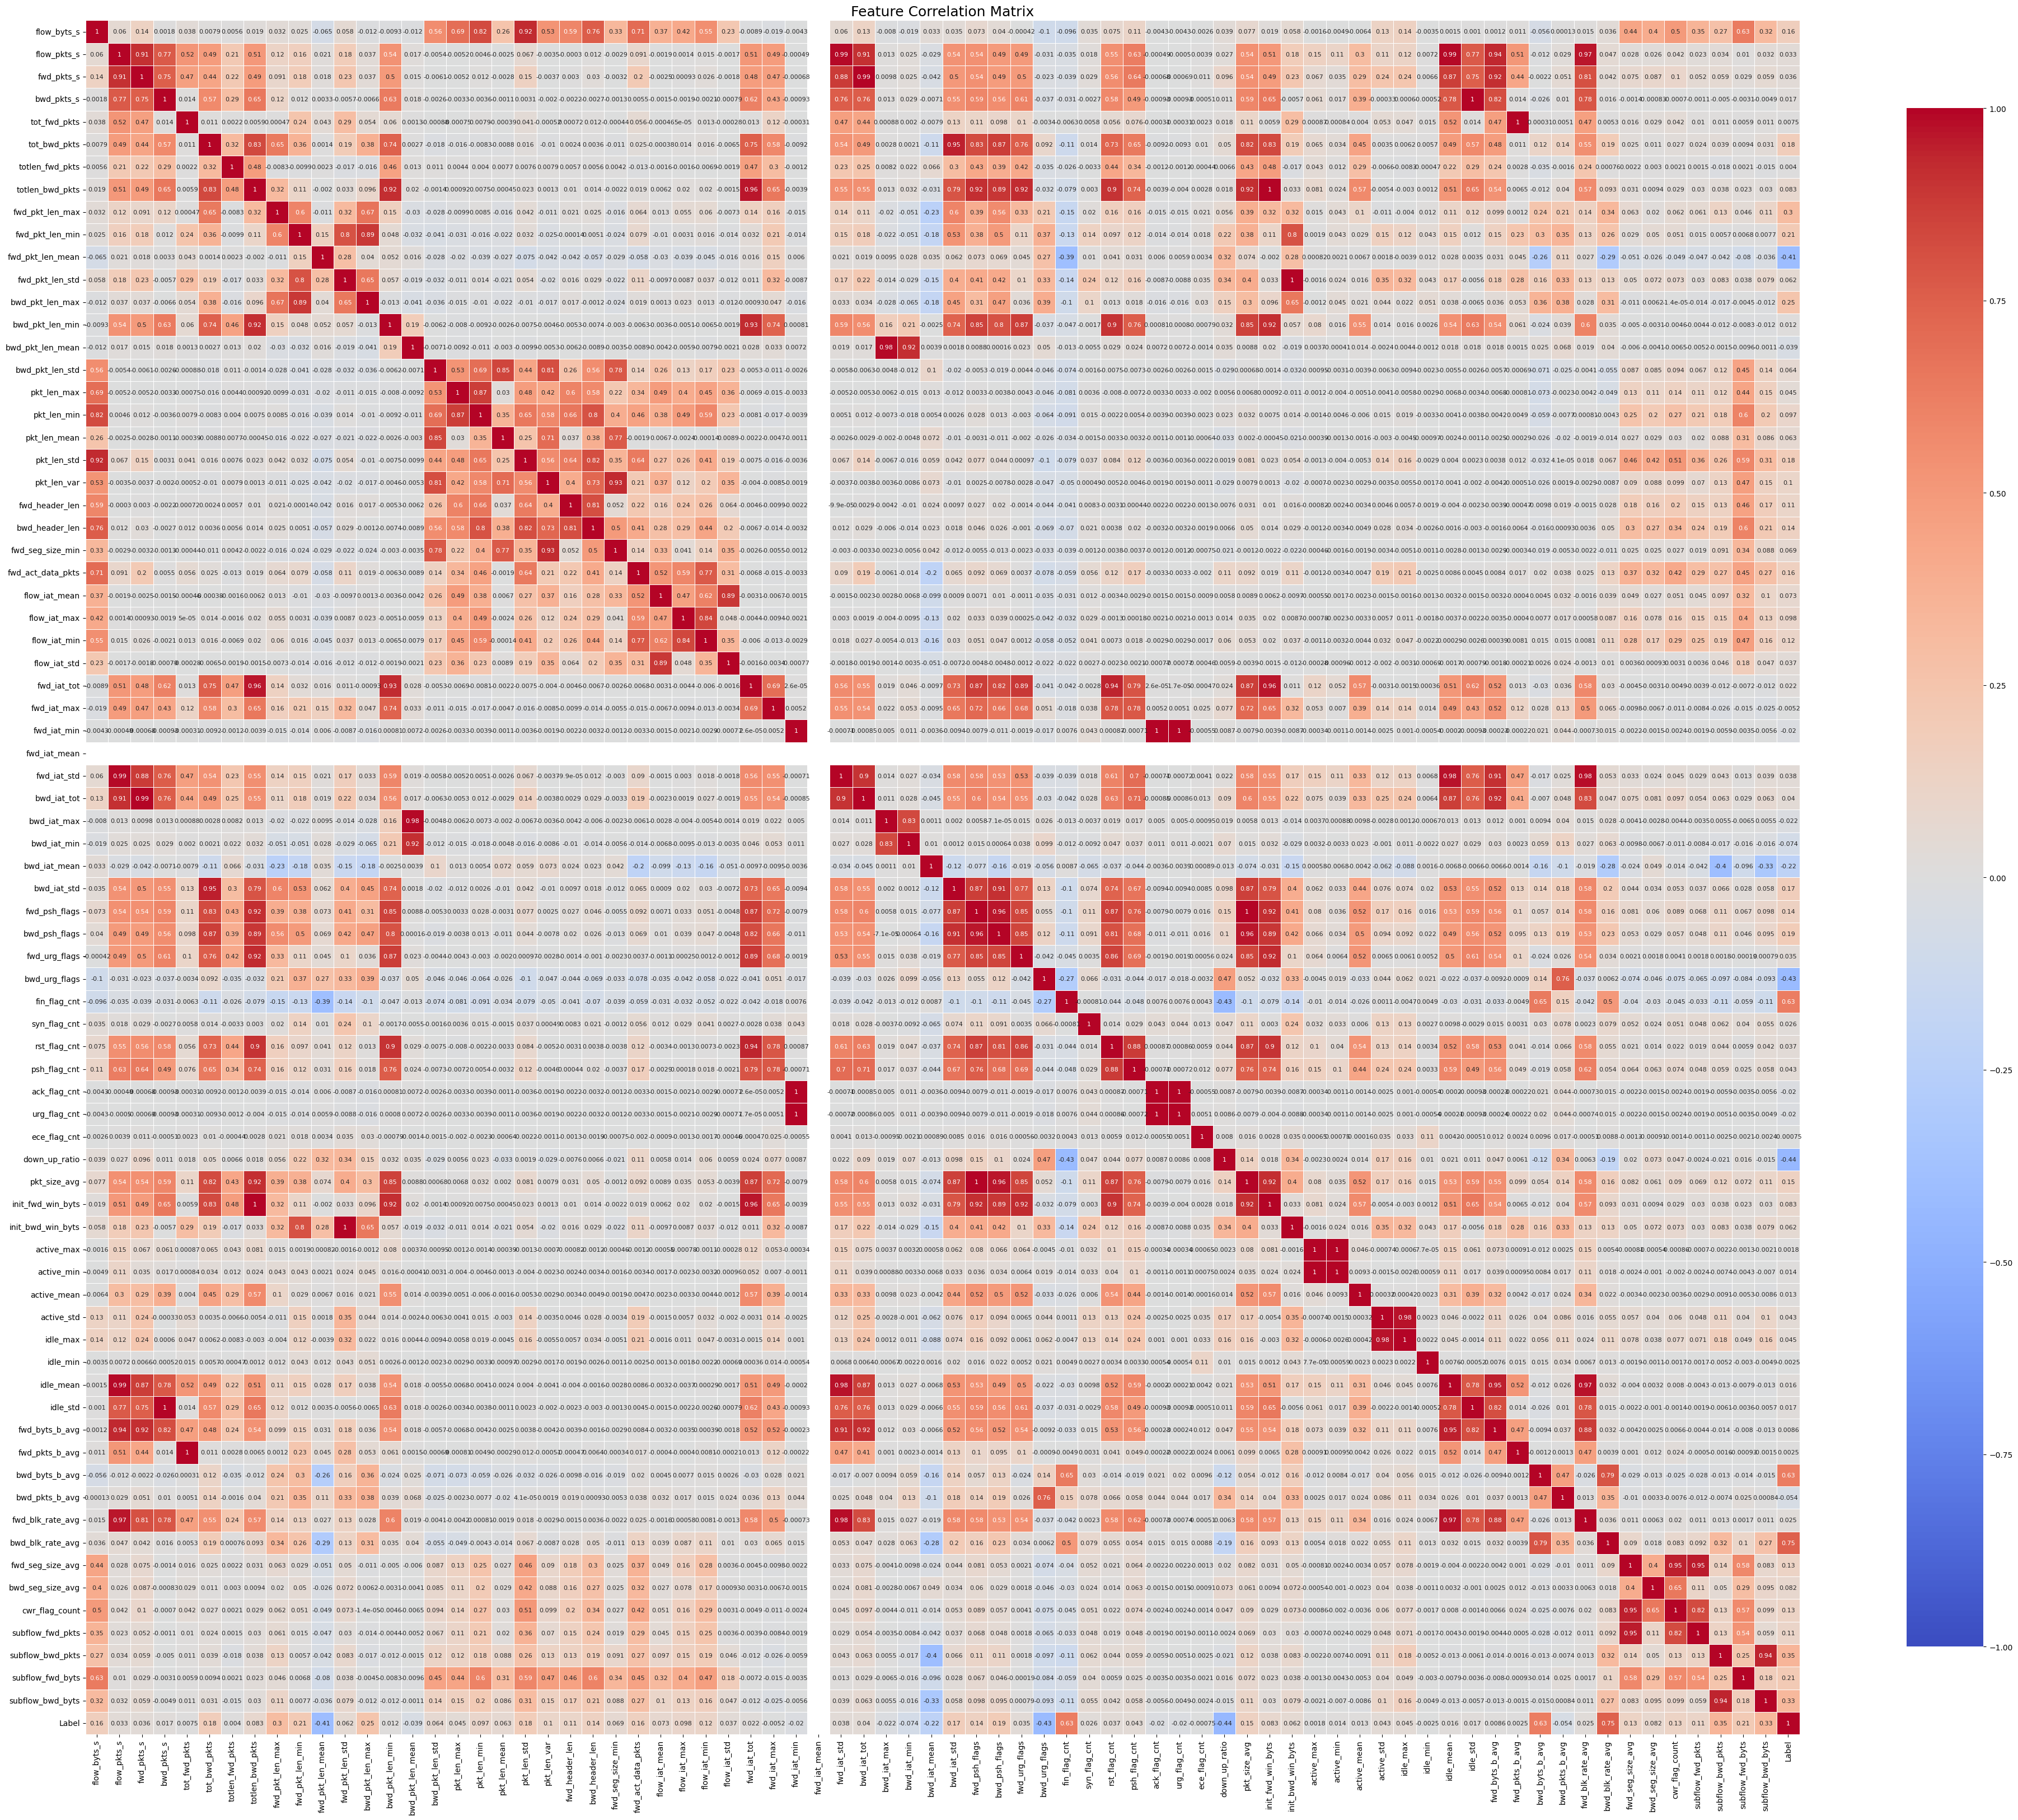

Top 20 highest correlations:
bwd_pkts_s        idle_std            0.999982
idle_std          bwd_pkts_s          0.999982
pkt_size_avg      fwd_psh_flags       0.999584
fwd_psh_flags     pkt_size_avg        0.999584
fwd_iat_min       urg_flag_cnt        0.997803
ack_flag_cnt      urg_flag_cnt        0.997803
urg_flag_cnt      fwd_iat_min         0.997803
                  ack_flag_cnt        0.997803
fwd_pkts_b_avg    tot_fwd_pkts        0.996540
tot_fwd_pkts      fwd_pkts_b_avg      0.996540
active_min        active_max          0.996097
active_max        active_min          0.996097
bwd_iat_tot       fwd_pkts_s          0.993161
fwd_pkts_s        bwd_iat_tot         0.993161
fwd_iat_std       flow_pkts_s         0.989200
flow_pkts_s       fwd_iat_std         0.989200
                  idle_mean           0.987455
idle_mean         flow_pkts_s         0.987455
bwd_pkt_len_mean  bwd_iat_max         0.984750
bwd_iat_max       bwd_pkt_len_mean    0.984750
dtype: float64


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

merged_df.rename(columns=COLUMN_MAPPING, inplace=True)
# List of features you provided
features = merged_df.columns

# Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()


plt.figure(figsize=(40, 35))  # Increase width and height to make boxes bigger

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={'size': 8}  # You can increase annotation font size if you want
)

plt.title('Feature Correlation Matrix', fontsize=18)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

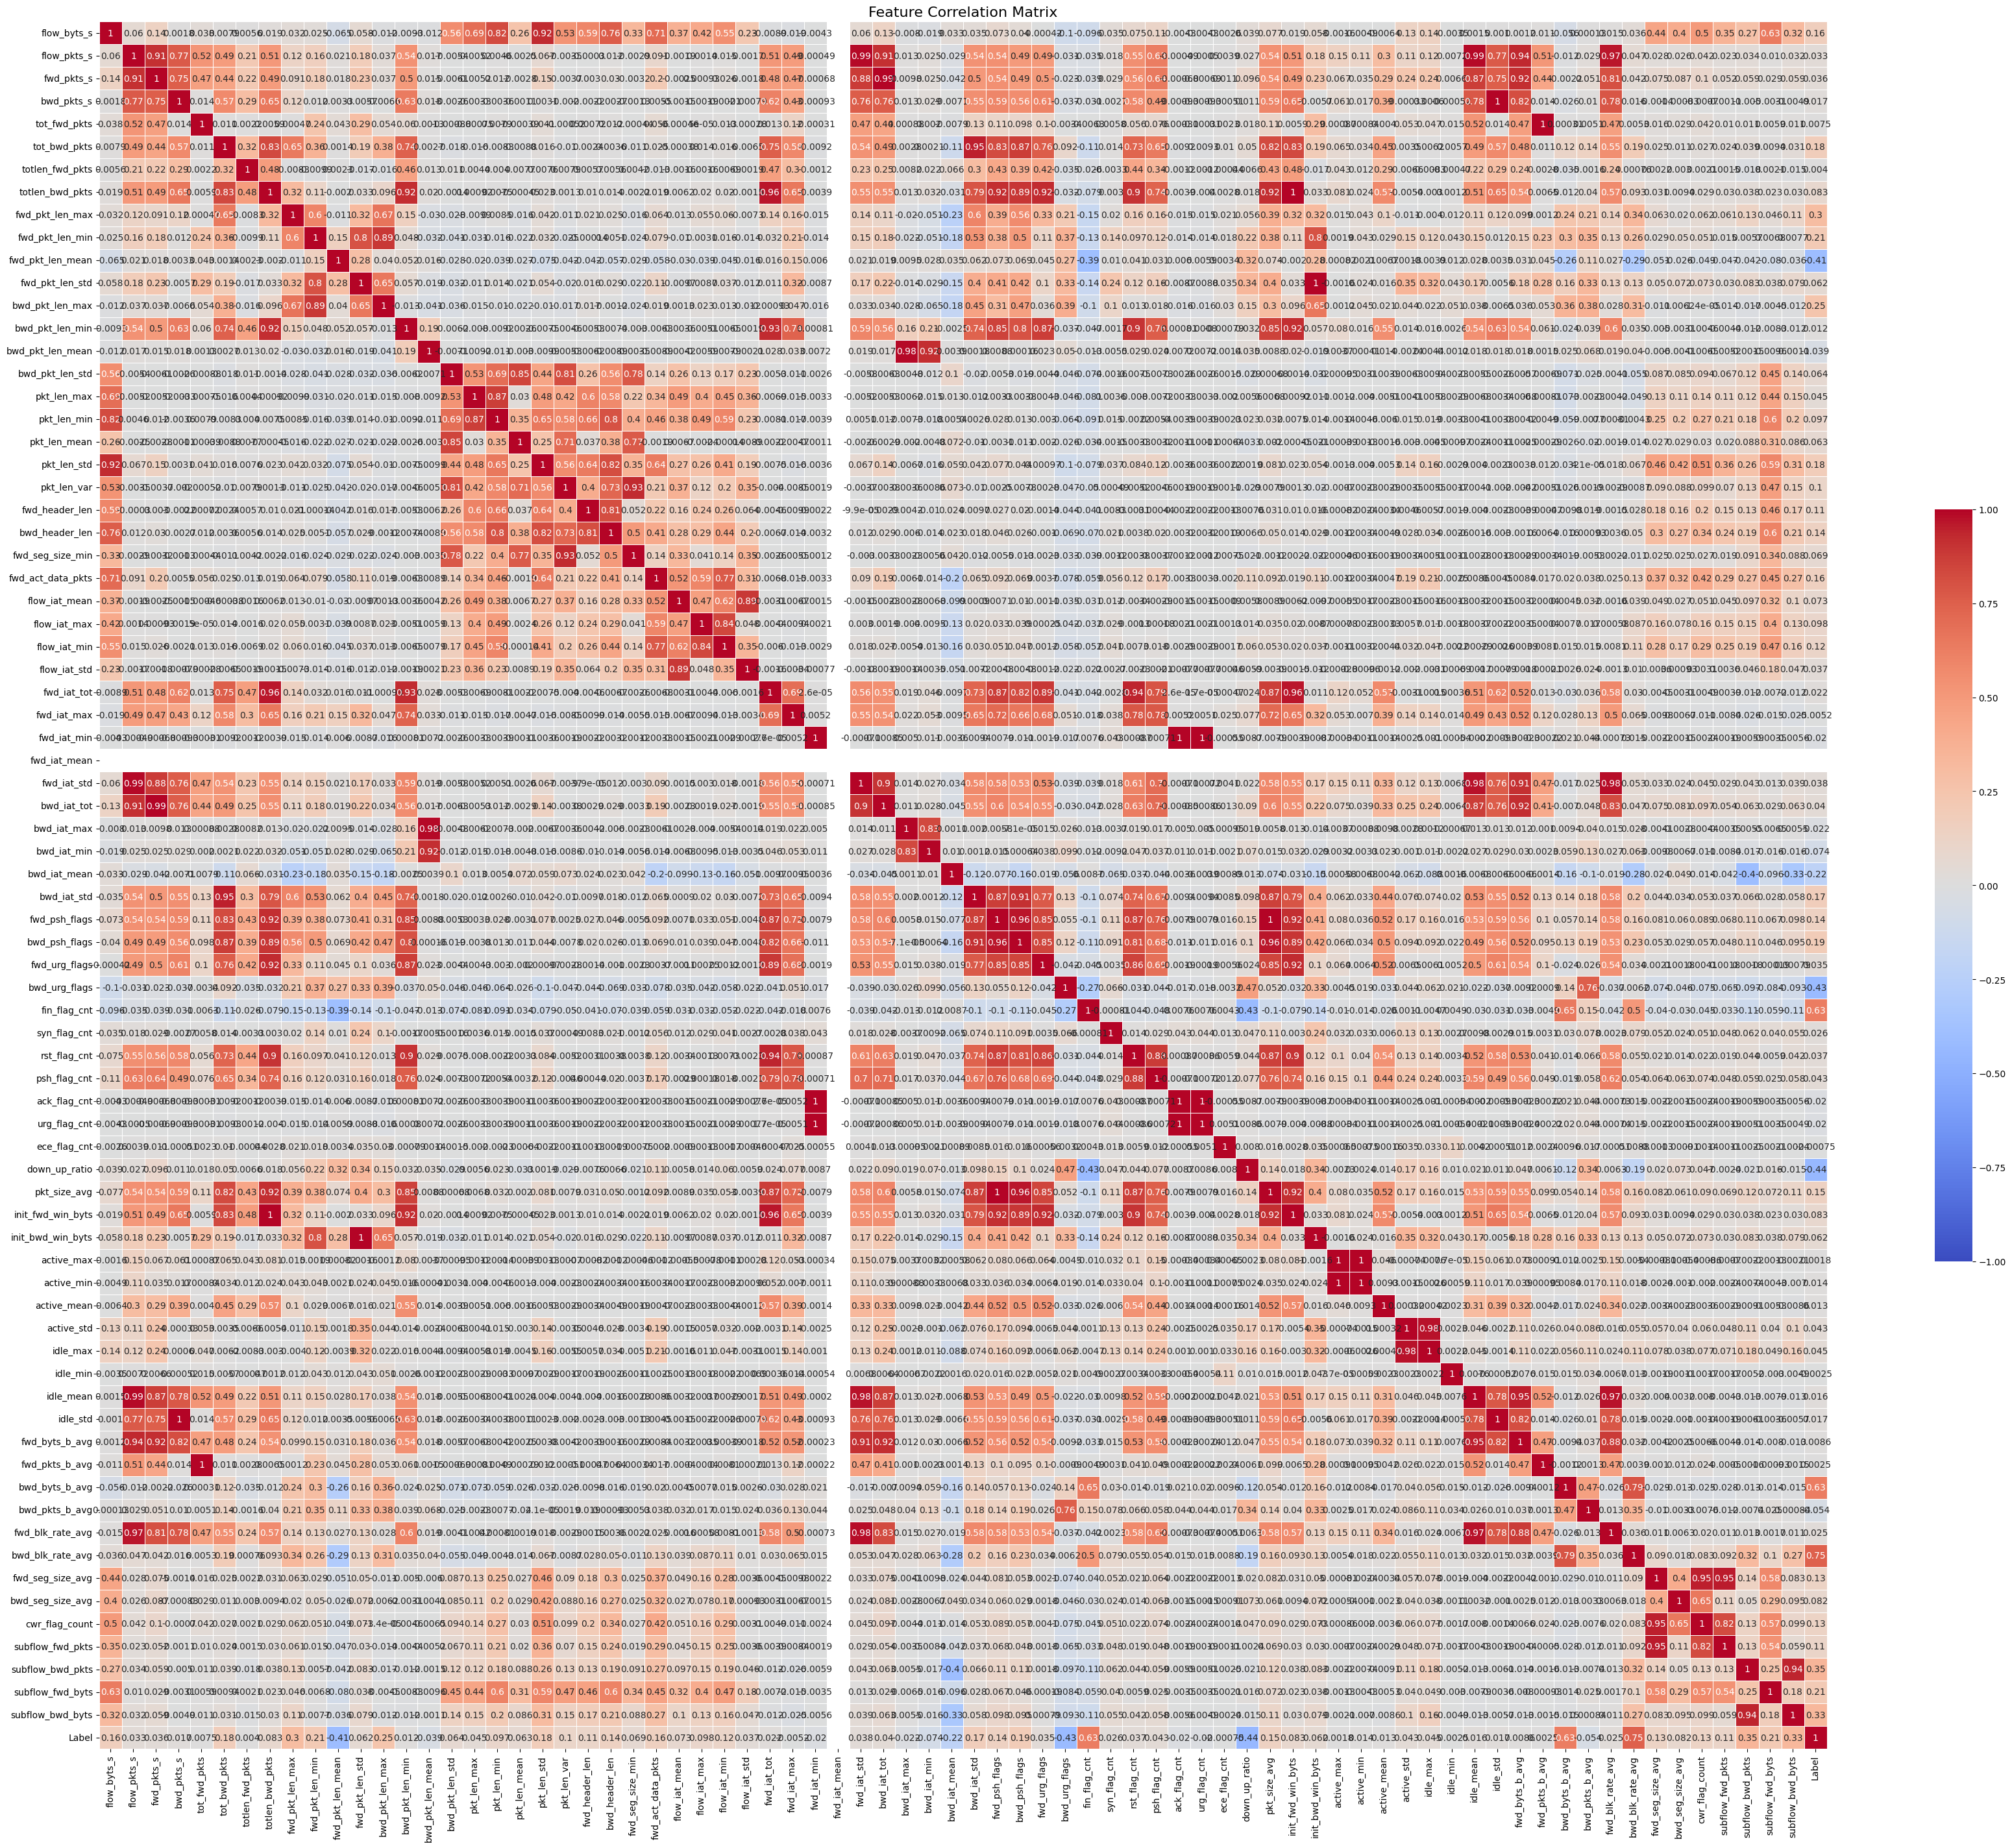

Top 20 highest correlations:
bwd_pkts_s        idle_std            0.999982
idle_std          bwd_pkts_s          0.999982
pkt_size_avg      fwd_psh_flags       0.999584
fwd_psh_flags     pkt_size_avg        0.999584
fwd_iat_min       urg_flag_cnt        0.997803
ack_flag_cnt      urg_flag_cnt        0.997803
urg_flag_cnt      fwd_iat_min         0.997803
                  ack_flag_cnt        0.997803
fwd_pkts_b_avg    tot_fwd_pkts        0.996540
tot_fwd_pkts      fwd_pkts_b_avg      0.996540
active_min        active_max          0.996097
active_max        active_min          0.996097
bwd_iat_tot       fwd_pkts_s          0.993161
fwd_pkts_s        bwd_iat_tot         0.993161
fwd_iat_std       flow_pkts_s         0.989200
flow_pkts_s       fwd_iat_std         0.989200
                  idle_mean           0.987455
idle_mean         flow_pkts_s         0.987455
bwd_pkt_len_mean  bwd_iat_max         0.984750
bwd_iat_max       bwd_pkt_len_mean    0.984750
dtype: float64


In [18]:

# List of features you provided
features = merged_df.columns


# Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(35, 30))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.7,
            cbar_kws={"shrink": 0.4},
            annot=True,
            annot_kws={'size':10})


plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

In [19]:
# Columns that should never be dropped
protected_cols = ['Label']

# Use only feature columns for correlation analysis
features_df = merged_df.drop(columns=protected_cols, errors='ignore')

# Compute absolute correlation matrix
corr_matrix = features_df.corr().abs()

# Create upper triangle of the correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Set correlation threshold
threshold = 0.7

# Find highly correlated features
to_drop = [
    column for column in upper.columns
    if any(upper[column] >= threshold)
]

print("Highly correlated features to drop (correlation ≥ 0.7):")
print(to_drop)

# Drop correlated features BUT keep protected columns
reduced_df = merged_df.drop(columns=to_drop, errors='ignore')

# Shapes before and after
print("Original shape:", merged_df.shape)
print("Reduced shape:", reduced_df.shape)


Highly correlated features to drop (correlation ≥ 0.7):
['fwd_pkts_s', 'bwd_pkts_s', 'totlen_bwd_pkts', 'fwd_pkt_len_std', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'bwd_header_len', 'fwd_seg_size_min', 'fwd_act_data_pkts', 'flow_iat_min', 'flow_iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_std', 'fwd_psh_flags', 'bwd_psh_flags', 'fwd_urg_flags', 'rst_flag_cnt', 'psh_flag_cnt', 'ack_flag_cnt', 'urg_flag_cnt', 'pkt_size_avg', 'init_fwd_win_byts', 'init_bwd_win_byts', 'active_min', 'idle_max', 'idle_mean', 'idle_std', 'fwd_byts_b_avg', 'fwd_pkts_b_avg', 'bwd_pkts_b_avg', 'fwd_blk_rate_avg', 'bwd_blk_rate_avg', 'cwr_flag_count', 'subflow_fwd_pkts', 'subflow_bwd_byts']
Original shape: (249721, 76)
Reduced shape: (249721, 32)


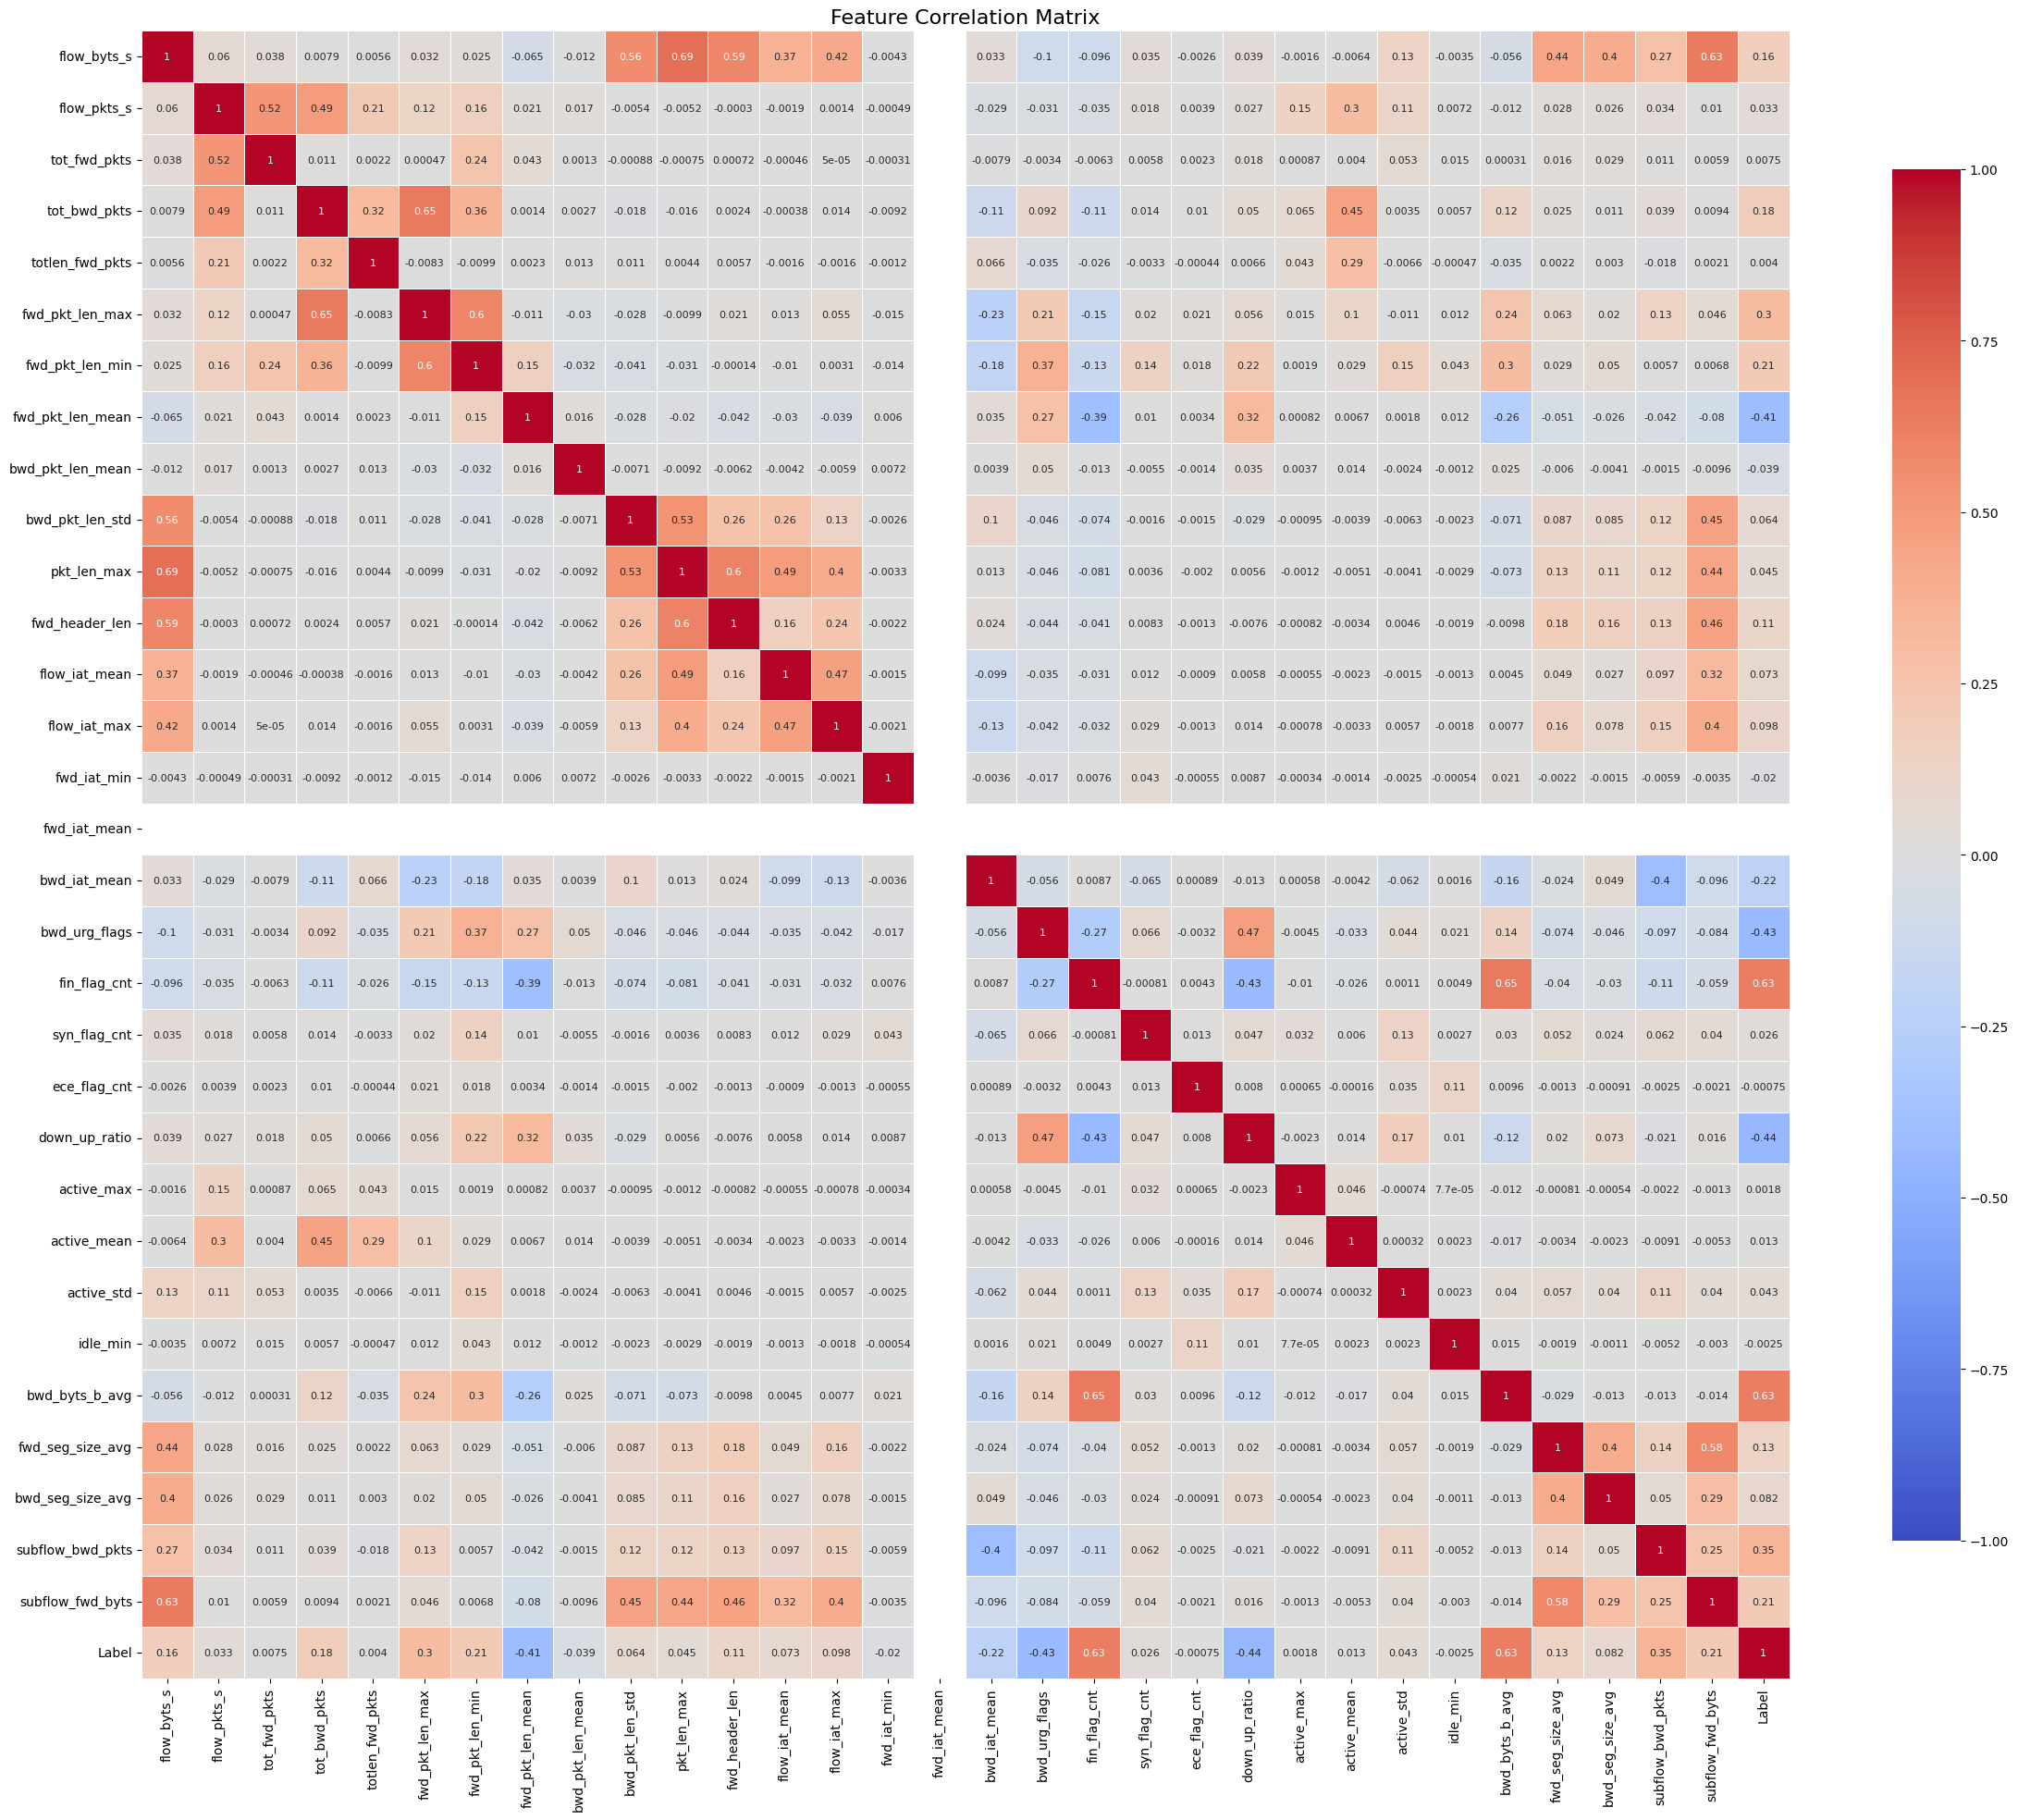

Top 20 highest correlations:
pkt_len_max       flow_byts_s         0.694199
flow_byts_s       pkt_len_max         0.694199
bwd_byts_b_avg    fin_flag_cnt        0.648300
fin_flag_cnt      bwd_byts_b_avg      0.648300
tot_bwd_pkts      fwd_pkt_len_max     0.645596
fwd_pkt_len_max   tot_bwd_pkts        0.645596
subflow_fwd_byts  flow_byts_s         0.633960
flow_byts_s       subflow_fwd_byts    0.633960
Label             fin_flag_cnt        0.632637
fin_flag_cnt      Label               0.632637
Label             bwd_byts_b_avg      0.626833
bwd_byts_b_avg    Label               0.626833
fwd_header_len    pkt_len_max         0.603859
pkt_len_max       fwd_header_len      0.603859
fwd_pkt_len_max   fwd_pkt_len_min     0.601459
fwd_pkt_len_min   fwd_pkt_len_max     0.601459
fwd_header_len    flow_byts_s         0.590013
flow_byts_s       fwd_header_len      0.590013
subflow_fwd_byts  fwd_seg_size_avg    0.582702
fwd_seg_size_avg  subflow_fwd_byts    0.582702
dtype: float64


In [20]:
# List of features you provided
features=reduced_df.columns
    # Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(24, 20))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            annot=True,
            annot_kws={'size':8})

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

In [21]:

# Keep only numeric columns from merged_df
numeric_df = reduced_df.select_dtypes(include=[np.number])

# Compute correlation matrix on numeric data
correlation_matrix = numeric_df.corr()

# Choose correlation column: 'Label' or 'Label_encoded'
target_column = 'Label'  # or 'Label_encoded' if using encoded labels

# Get correlation of all features with the label column
label_corr = correlation_matrix[target_column]

# Set threshold
threshold = 0.001

# Keep only features with abs(correlation) > threshold
features_to_keep = label_corr[abs(label_corr) > threshold].index.tolist()

# Ensure the target column is included
if target_column not in features_to_keep:
    features_to_keep.append(target_column)

# Filter original merged_df using the selected numeric features
merged_df = merged_df[features_to_keep]

# Print results
print("Kept features:", features_to_keep)
print("Filtered shape:", merged_df.shape)


Kept features: ['flow_byts_s', 'flow_pkts_s', 'tot_fwd_pkts', 'tot_bwd_pkts', 'totlen_fwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'pkt_len_max', 'fwd_header_len', 'flow_iat_mean', 'flow_iat_max', 'fwd_iat_min', 'bwd_iat_mean', 'bwd_urg_flags', 'fin_flag_cnt', 'syn_flag_cnt', 'down_up_ratio', 'active_max', 'active_mean', 'active_std', 'idle_min', 'bwd_byts_b_avg', 'fwd_seg_size_avg', 'bwd_seg_size_avg', 'subflow_bwd_pkts', 'subflow_fwd_byts', 'Label']
Filtered shape: (249721, 30)


In [22]:
merged_df.to_csv("final_dataset.csv", index=False)

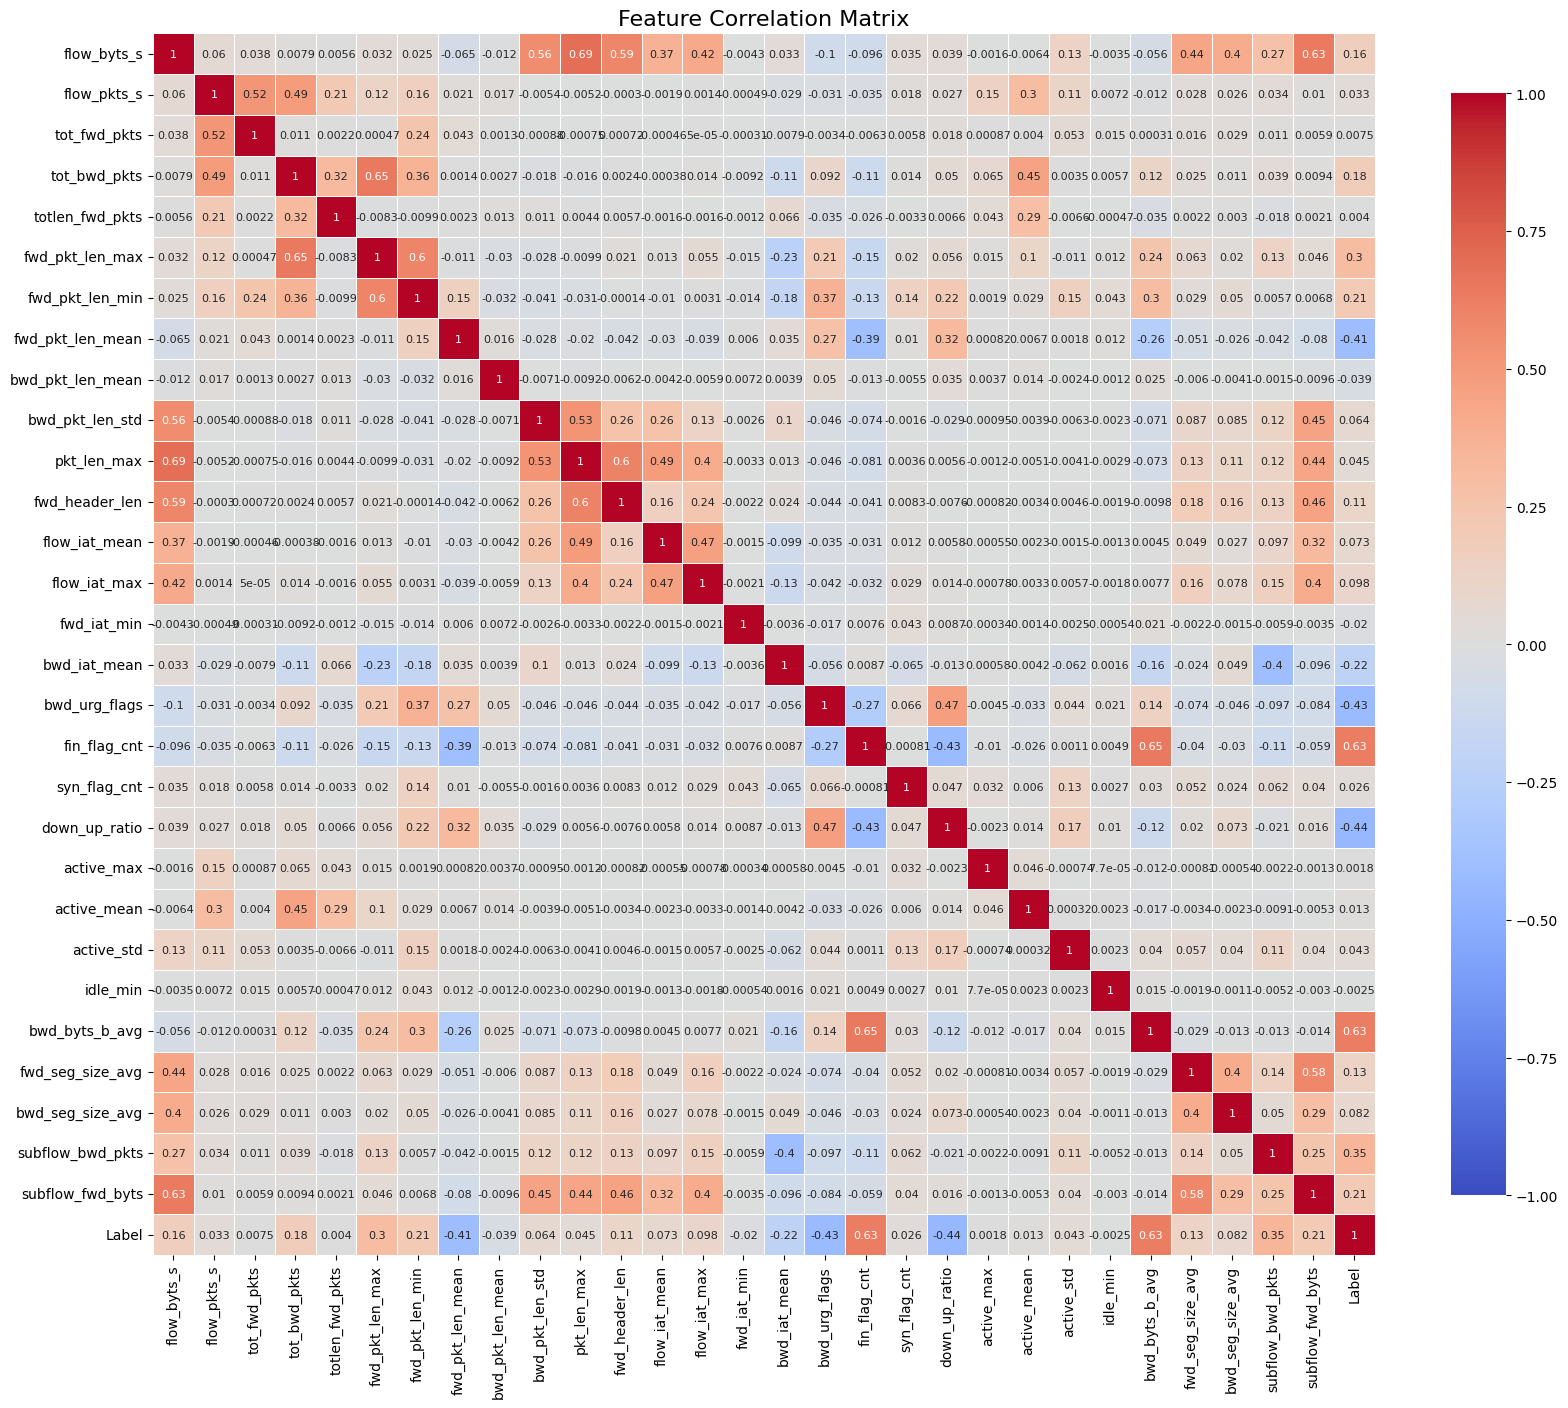

Saved: Feature_Correlation_Matrix.png


In [23]:
# List of features you provided
features=merged_df.columns
    # Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
# Set up the matplotlib figure
plt.figure(figsize=(17, 15))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            annot=True,
            annot_kws={'size':8})

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Save heatmap as PNG
plt.savefig(
    "Feature_Correlation_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Feature_Correlation_Matrix.png")

Remaining samples after outlier removal: 242235


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw



RANDOM FOREST - TRAINING PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       0.97      0.99      0.98     17629
         SSH       1.00      0.99      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      0.90      0.94      2738

    accuracy                           1.00    169564
   macro avg       0.99      0.98      0.99    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9964
Precision : 0.9965
Recall    : 0.9964
F1 Score  : 0.9964


<Figure size 800x600 with 0 Axes>

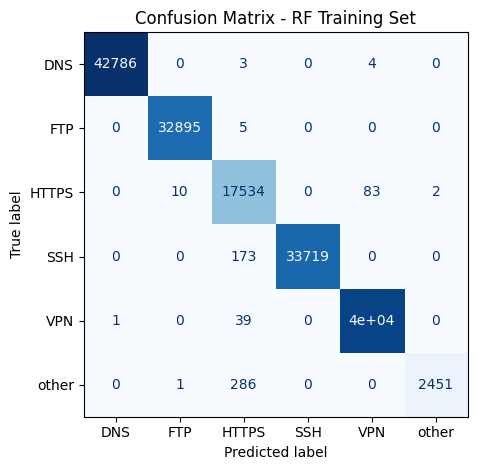


RANDOM FOREST - TEST PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       0.97      1.00      0.98      7555
         SSH       1.00      0.99      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      0.91      0.95      1173

    accuracy                           1.00     72671
   macro avg       1.00      0.98      0.99     72671
weighted avg       1.00      1.00      1.00     72671

Test Metrics:
Accuracy  : 0.9967
Precision : 0.9967
Recall    : 0.9967
F1 Score  : 0.9966
Saved: RF_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

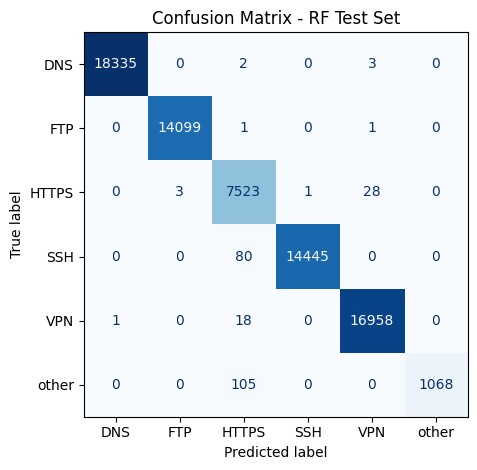


FINAL MODEL PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.996420   0.996487  0.996420  0.996393
1   Testing  0.996656   0.996720  0.996656  0.996640


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import Pipeline


# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

# Temporary imputation for Isolation Forest
X_imputed = SimpleImputer(strategy="mean").fit_transform(X)

mask = iso.fit_predict(X_imputed) == 1

X = X[mask]
y = y[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# =========================================================
# 4. RANDOM FOREST PIPELINE
# =========================================================

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),

    ("select", SelectKBest(
        score_func=f_classif
    )),

    ("rf", RandomForestClassifier(
        n_estimators=100,
        max_depth=4,
        random_state=3,
        n_jobs=-1
    ))
])


# =========================================================
# 5. MODEL TRAINING
# =========================================================

rf_pipeline.fit(
    X_train,
    y_train
)


# =========================================================
# 6. TRAINING SET PREDICTION
# =========================================================

y_train_pred = rf_pipeline.predict(X_train)


# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n==============================")
print("RANDOM FOREST - TRAINING PERFORMANCE")
print("==============================")

print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)


train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

train_precision = precision_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_recall = recall_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_f1 = f1_score(
    y_train,
    y_train_pred,
    average="weighted"
)


print("Training Metrics:")
print(f"Accuracy  : {train_accuracy:.4f}")
print(f"Precision : {train_precision:.4f}")
print(f"Recall    : {train_recall:.4f}")
print(f"F1 Score  : {train_f1:.4f}")


# Training Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - RF Training Set")
plt.tight_layout()
plt.show()



# =========================================================
# 8. TEST SET PREDICTION
# =========================================================

y_test_pred = rf_pipeline.predict(X_test)



# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n==============================")
print("RANDOM FOREST - TEST PERFORMANCE")
print("==============================")


print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)


print("Test Metrics:")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")



# Test Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - RF Test Set")
plt.tight_layout()

# Save as high-resolution PNG
plt.savefig(
    "RF_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: RF_Test_Confusion_Matrix.png")

plt.show()



# =========================================================
# 10. FINAL SUMMARY TABLE
# =========================================================

results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [train_accuracy, test_accuracy],
    "Precision": [train_precision, test_precision],
    "Recall": [train_recall, test_recall],
    "F1 Score": [train_f1, test_f1]
})


print("\nFINAL MODEL PERFORMANCE SUMMARY")
print(results)

In [25]:
# =========================================================
# 10. SAVE MODEL + SELECTED FEATURES (OPTIONAL)
# =========================================================
import joblib
joblib.dump(rf_pipeline, "RF_model.pkl")

# 1️ Save all features used to train the model (before SelectKBest)
all_features = X_train.columns.tolist()  # original numeric columns
joblib.dump(all_features, "RF_features.pkl")

print(f"Saved RF_model.pkl and RF_features.pkl (all {len(all_features)} features)")
# import joblib

joblib.dump(rf_pipeline, "RF_model.pkl")

selected_features = X_train.columns.tolist() 

joblib.dump(selected_features, "RF_features.pkl")

print("\nSaved RF_model.pkl and RF_features.pkl")

Saved RF_model.pkl and RF_features.pkl (all 29 features)

Saved RF_model.pkl and RF_features.pkl


Remaining samples after outlier removal: 242235

Training MLP Model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw



MLP - TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       1.00      1.00      1.00     17629
         SSH       1.00      1.00      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      1.00      1.00      2738

    accuracy                           1.00    169564
   macro avg       1.00      1.00      1.00    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9996
Precision : 0.9996
Recall    : 0.9996
F1 Score  : 0.9996


<Figure size 800x600 with 0 Axes>

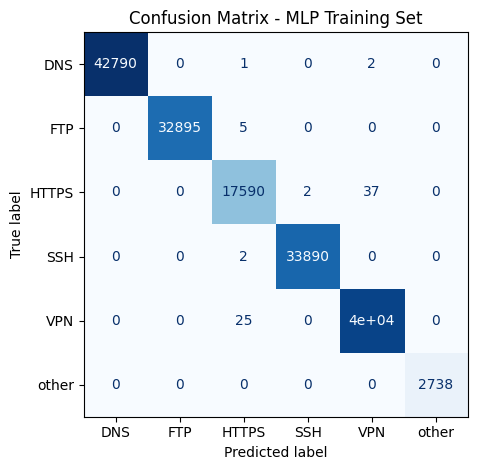


MLP - TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       1.00      1.00      1.00      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      1.00      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Testing Metrics:
Accuracy  : 0.9995
Precision : 0.9995
Recall    : 0.9995
F1 Score  : 0.9995
Saved: MLP_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

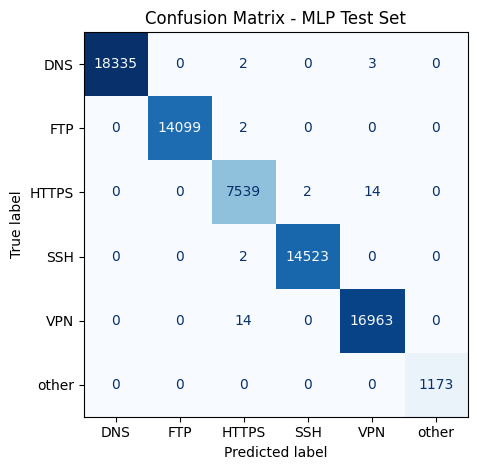


FINAL MLP PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.999564   0.999564  0.999564  0.999564
1   Testing  0.999463   0.999464  0.999463  0.999463

MLP_model.pkl saved successfully!


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

import joblib


# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]



# =========================================================
# 2. OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)


# Temporary imputation for outlier detection
X_imputed = SimpleImputer(strategy="mean").fit_transform(X)

mask = iso.fit_predict(X_imputed) == 1

X = X[mask]
y = y[mask]


print(f"Remaining samples after outlier removal: {len(X)}")



# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)



# =========================================================
# 4. MLP PIPELINE
# =========================================================

mlp_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="mean")),

    ("select", SelectKBest(
        score_func=f_classif
    )),

    ("scaler", StandardScaler()),

    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64,32),
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=42
    ))
])



# =========================================================
# 5. MODEL TRAINING
# =========================================================

print("\nTraining MLP Model...")

mlp_pipeline.fit(
    X_train,
    y_train
)



# =========================================================
# 6. TRAINING PREDICTION
# =========================================================

y_train_pred = mlp_pipeline.predict(X_train)



# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n===================================")
print("MLP - TRAINING SET PERFORMANCE")
print("===================================")


print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

train_precision = precision_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_recall = recall_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_f1 = f1_score(
    y_train,
    y_train_pred,
    average="weighted"
)



print("Training Metrics:")
print(f"Accuracy  : {train_accuracy:.4f}")
print(f"Precision : {train_precision:.4f}")
print(f"Recall    : {train_recall:.4f}")
print(f"F1 Score  : {train_f1:.4f}")



# Training Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - MLP Training Set")
plt.tight_layout()
plt.show()




# =========================================================
# 8. TESTING PREDICTION
# =========================================================

y_test_pred_mlp = mlp_pipeline.predict(X_test)




# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n===================================")
print("MLP - TEST SET PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_test,
        y_test_pred_mlp,
        target_names=label_encoder.classes_.astype(str)
    )
)



test_accuracy = accuracy_score(
    y_test,
    y_test_pred_mlp
)

test_precision = precision_score(
    y_test,
    y_test_pred_mlp,
    average="weighted"
)

test_recall = recall_score(
    y_test,
    y_test_pred_mlp,
    average="weighted"
)

test_f1 = f1_score(
    y_test,
    y_test_pred_mlp,
    average="weighted"
)



print("Testing Metrics:")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")



# Test Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_mlp,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - MLP Test Set")
plt.tight_layout()
# Save as high-resolution PNG
plt.savefig(
    "MLP_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)


print("Saved: MLP_Test_Confusion_Matrix.png")
plt.show()




# =========================================================
# 10. FINAL PERFORMANCE SUMMARY
# =========================================================

results = pd.DataFrame({

    "Dataset": [
        "Training",
        "Testing"
    ],

    "Accuracy": [
        train_accuracy,
        test_accuracy
    ],

    "Precision": [
        train_precision,
        test_precision
    ],

    "Recall": [
        train_recall,
        test_recall
    ],

    "F1 Score": [
        train_f1,
        test_f1
    ]

})


print("\nFINAL MLP PERFORMANCE SUMMARY")
print(results)



# =========================================================
# 11. SAVE MODEL
# =========================================================

joblib.dump(
    mlp_pipeline,
    "MLP_model.pkl"
)


print("\nMLP_model.pkl saved successfully!")

In [27]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


Remaining samples after outlier removal: 242235

Training XGBoost Model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw



XGBOOST - TRAINING PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       1.00      1.00      1.00     17629
         SSH       1.00      1.00      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      1.00      1.00      2738

    accuracy                           1.00    169564
   macro avg       1.00      1.00      1.00    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9998
Precision : 0.9998
Recall    : 0.9998
F1 Score  : 0.9998


<Figure size 800x600 with 0 Axes>

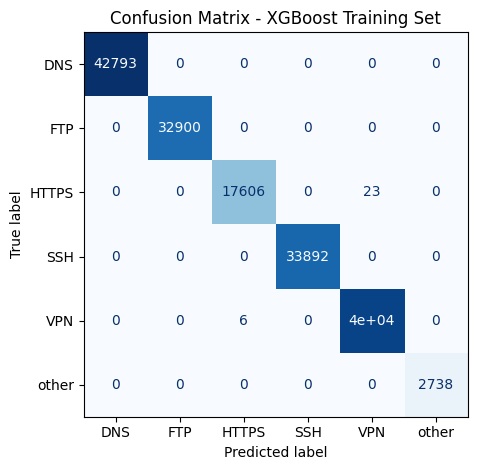


XGBOOST - TEST PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       1.00      1.00      1.00      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      1.00      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Testing Metrics:
Accuracy  : 0.9997
Precision : 0.9997
Recall    : 0.9997
F1 Score  : 0.9997
Saved: XGB_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

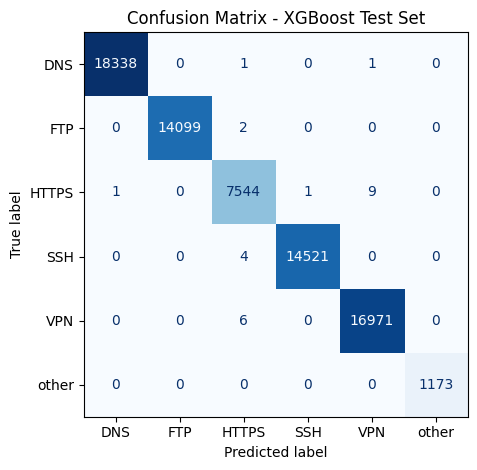


FINAL XGBOOST PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.999829   0.999829  0.999829  0.999829
1   Testing  0.999656   0.999656  0.999656  0.999656

XGB_model.pkl saved successfully!


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier

import joblib



# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)


X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]




# =========================================================
# 2. OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)


X_imputed = SimpleImputer(strategy="mean").fit_transform(X)

mask = iso.fit_predict(X_imputed) == 1


X = X[mask]
y = y[mask]


print(f"Remaining samples after outlier removal: {len(X)}")




# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)




# =========================================================
# 4. XGBOOST PIPELINE
# =========================================================

xgb_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="mean")),

    ("select", SelectKBest(
        score_func=f_classif
    )),


    ("xgb", XGBClassifier(

        n_estimators=150,

        max_depth=4,

        learning_rate=0.1,

        subsample=0.8,

        colsample_bytree=0.8,

        eval_metric="mlogloss",

        random_state=42,

        n_jobs=-1
    ))
])




# =========================================================
# 5. MODEL TRAINING
# =========================================================

print("\nTraining XGBoost Model...")

xgb_pipeline.fit(
    X_train,
    y_train
)




# =========================================================
# 6. TRAINING PREDICTION
# =========================================================

y_train_pred_xgb = xgb_pipeline.predict(
    X_train
)




# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n===================================")
print("XGBOOST - TRAINING PERFORMANCE")
print("===================================")


print(
    classification_report(
        y_train,
        y_train_pred_xgb,
        target_names=label_encoder.classes_.astype(str)
    )
)



train_accuracy = accuracy_score(
    y_train,
    y_train_pred_xgb
)

train_precision = precision_score(
    y_train,
    y_train_pred_xgb,
    average="weighted"
)

train_recall = recall_score(
    y_train,
    y_train_pred_xgb,
    average="weighted"
)

train_f1 = f1_score(
    y_train,
    y_train_pred_xgb,
    average="weighted"
)



print("Training Metrics:")
print(f"Accuracy  : {train_accuracy:.4f}")
print(f"Precision : {train_precision:.4f}")
print(f"Recall    : {train_recall:.4f}")
print(f"F1 Score  : {train_f1:.4f}")




# Training Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred_xgb,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)


plt.title("Confusion Matrix - XGBoost Training Set")
plt.tight_layout()
plt.show()





# =========================================================
# 8. TESTING PREDICTION
# =========================================================

y_test_pred_xgb = xgb_pipeline.predict(
    X_test
)




# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n===================================")
print("XGBOOST - TEST PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_test,
        y_test_pred_xgb,
        target_names=label_encoder.classes_.astype(str)
    )
)




test_accuracy = accuracy_score(
    y_test,
    y_test_pred_xgb
)

test_precision = precision_score(
    y_test,
    y_test_pred_xgb,
    average="weighted"
)

test_recall = recall_score(
    y_test,
    y_test_pred_xgb,
    average="weighted"
)

test_f1 = f1_score(
    y_test,
    y_test_pred_xgb,
    average="weighted"
)



print("Testing Metrics:")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")





# Test Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_xgb,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)


plt.title("Confusion Matrix - XGBoost Test Set")
plt.tight_layout()

# Save as high-resolution PNG
plt.savefig(
    "XGB_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: XGB_Test_Confusion_Matrix.png")

plt.show()





# =========================================================
# 10. FINAL PERFORMANCE SUMMARY
# =========================================================

results = pd.DataFrame({

    "Dataset": [
        "Training",
        "Testing"
    ],

    "Accuracy": [
        train_accuracy,
        test_accuracy
    ],

    "Precision": [
        train_precision,
        test_precision
    ],

    "Recall": [
        train_recall,
        test_recall
    ],

    "F1 Score": [
        train_f1,
        test_f1
    ]

})


print("\nFINAL XGBOOST PERFORMANCE SUMMARY")
print(results)




# =========================================================
# 11. SAVE MODEL
# =========================================================

joblib.dump(
    xgb_pipeline,
    "XGB_model.pkl"
)


print("\nXGB_model.pkl saved successfully!")

Remaining samples after outlier removal: 242235

Training KNN Model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw



KNN - TRAINING PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       1.00      1.00      1.00     17629
         SSH       1.00      1.00      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      1.00      1.00      2738

    accuracy                           1.00    169564
   macro avg       1.00      1.00      1.00    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9996
Precision : 0.9996
Recall    : 0.9996
F1 Score  : 0.9996


<Figure size 800x600 with 0 Axes>

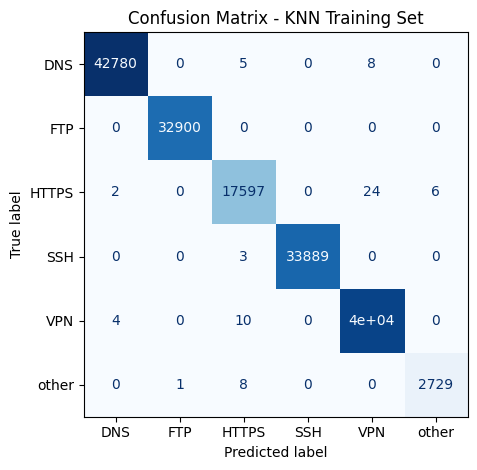


KNN - TEST PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       1.00      1.00      1.00      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       0.99      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      1.00      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Testing Metrics:
Accuracy  : 0.9994
Precision : 0.9994
Recall    : 0.9994
F1 Score  : 0.9994
Saved: KNN_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

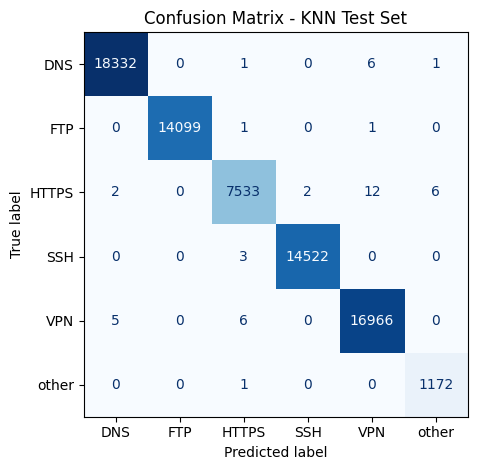


FINAL KNN PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.999581   0.999581  0.999581  0.999581
1   Testing  0.999353   0.999354  0.999353  0.999353

KNN_model.pkl and KNN_features.pkl saved successfully!


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

import joblib



# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)


X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]




# =========================================================
# 2. OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)


X_imputed = SimpleImputer(strategy="mean").fit_transform(X)

mask = iso.fit_predict(X_imputed) == 1


X = X[mask]
y = y[mask]


print(f"Remaining samples after outlier removal: {len(X)}")





# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)




# =========================================================
# 4. KNN PIPELINE
# =========================================================

knn_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="mean")),


    ("select", SelectKBest(
        score_func=f_classif
    )),


    ("knn", KNeighborsClassifier(

        n_neighbors=3,

        weights="uniform",

        metric="minkowski",

        p=2,

        n_jobs=-1
    ))
])





# =========================================================
# 5. TRAIN KNN MODEL
# =========================================================

print("\nTraining KNN Model...")

knn_pipeline.fit(
    X_train,
    y_train
)





# =========================================================
# 6. TRAINING PREDICTION
# =========================================================

y_train_pred = knn_pipeline.predict(
    X_train
)





# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n===================================")
print("KNN - TRAINING PERFORMANCE")
print("===================================")


print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

train_precision = precision_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_recall = recall_score(
    y_train,
    y_train_pred,
    average="weighted"
)

train_f1 = f1_score(
    y_train,
    y_train_pred,
    average="weighted"
)



print("Training Metrics:")
print(f"Accuracy  : {train_accuracy:.4f}")
print(f"Precision : {train_precision:.4f}")
print(f"Recall    : {train_recall:.4f}")
print(f"F1 Score  : {train_f1:.4f}")





# Training Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - KNN Training Set")
plt.tight_layout()
plt.show()






# =========================================================
# 8. TEST PREDICTION
# =========================================================

y_test_pred = knn_pipeline.predict(
    X_test
)





# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n===================================")
print("KNN - TEST PERFORMANCE")
print("===================================")


print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)




test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)



print("Testing Metrics:")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")





# Test Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)


plt.title("Confusion Matrix - KNN Test Set")
plt.tight_layout()
plt.savefig(
    "KNN_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: KNN_Test_Confusion_Matrix.png")

plt.show()





# =========================================================
# 10. FINAL PERFORMANCE SUMMARY
# =========================================================

results = pd.DataFrame({

    "Dataset": [
        "Training",
        "Testing"
    ],

    "Accuracy": [
        train_accuracy,
        test_accuracy
    ],

    "Precision": [
        train_precision,
        test_precision
    ],

    "Recall": [
        train_recall,
        test_recall
    ],

    "F1 Score": [
        train_f1,
        test_f1
    ]

})


print("\nFINAL KNN PERFORMANCE SUMMARY")
print(results)





# =========================================================
# 11. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(
    knn_pipeline,
    "KNN_model.pkl"
)



# Save selected feature names

imputer = knn_pipeline.named_steps["imputer"]

selector = knn_pipeline.named_steps["select"]


feature_names = imputer.get_feature_names_out()

selected_features = feature_names[
    selector.get_support()
]


joblib.dump(
    selected_features.tolist(),
    "KNN_features.pkl"
)


print("\nKNN_model.pkl and KNN_features.pkl saved successfully!")

Remaining samples after outlier removal: 242235

Training Logistic Regression Model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



LOGISTIC REGRESSION - TRAINING PERFORMANCE
              precision    recall  f1-score   support

         DNS       0.99      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       0.99      0.97      0.98     17629
         SSH       1.00      1.00      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      1.00      1.00      2738

    accuracy                           1.00    169564
   macro avg       1.00      0.99      1.00    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9962
Precision : 0.9962
Recall    : 0.9962
F1 Score  : 0.9962


<Figure size 800x600 with 0 Axes>

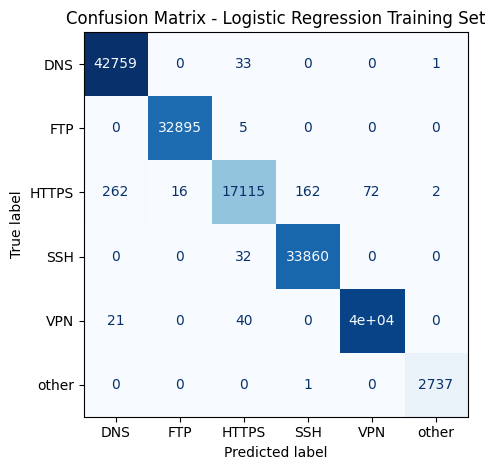


LOGISTIC REGRESSION - TEST PERFORMANCE
              precision    recall  f1-score   support

         DNS       0.99      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       0.99      0.97      0.98      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      0.99      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Testing Metrics:
Accuracy  : 0.9962
Precision : 0.9962
Recall    : 0.9962
F1 Score  : 0.9962
Saved: LR_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

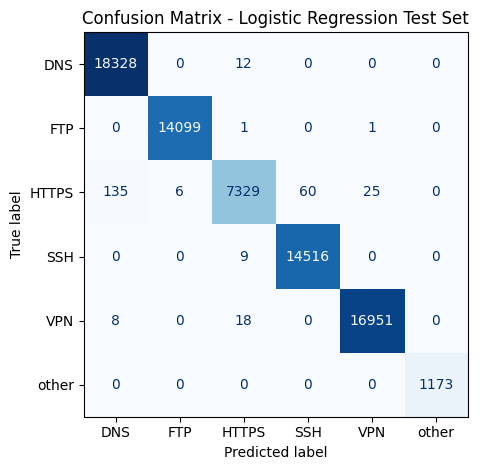


FINAL LOGISTIC REGRESSION PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.996184   0.996183  0.996184  0.996167
1   Testing  0.996216   0.996219  0.996216  0.996198

LogisticRegression_model.pkl and LogisticRegression_features.pkl saved successfully!


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import joblib



# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)


X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])

y = merged_df["Label"]





# =========================================================
# 2. OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)


X_imputed = SimpleImputer(strategy="mean").fit_transform(X)


mask = iso.fit_predict(X_imputed) == 1


X = X[mask]

y = y[mask]


print(f"Remaining samples after outlier removal: {len(X)}")





# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.3,

    stratify=y,

    random_state=42
)





# =========================================================
# 4. LOGISTIC REGRESSION PIPELINE
# =========================================================

logreg_pipeline = Pipeline([


    ("imputer", SimpleImputer(strategy="mean")),


    ("select", SelectKBest(
        score_func=f_classif
    )),


    ("scaler", StandardScaler()),



    ("logreg", LogisticRegression(

        penalty="l2",

        C=1.0,

        solver="lbfgs",

        max_iter=1000,

        multi_class="auto",

        random_state=42,

        n_jobs=-1

    ))

])





# =========================================================
# 5. TRAIN MODEL
# =========================================================

print("\nTraining Logistic Regression Model...")

logreg_pipeline.fit(
    X_train,
    y_train
)





# =========================================================
# 6. TRAINING PREDICTION
# =========================================================

y_train_pred = logreg_pipeline.predict(
    X_train
)





# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n===================================")
print("LOGISTIC REGRESSION - TRAINING PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)


train_precision = precision_score(
    y_train,
    y_train_pred,
    average="weighted"
)


train_recall = recall_score(
    y_train,
    y_train_pred,
    average="weighted"
)


train_f1 = f1_score(
    y_train,
    y_train_pred,
    average="weighted"
)



print("Training Metrics:")

print(f"Accuracy  : {train_accuracy:.4f}")

print(f"Precision : {train_precision:.4f}")

print(f"Recall    : {train_recall:.4f}")

print(f"F1 Score  : {train_f1:.4f}")





# Training Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(

    y_train,

    y_train_pred,

    display_labels=label_encoder.classes_.astype(str),

    cmap="Blues",

    colorbar=False

)


plt.title("Confusion Matrix - Logistic Regression Training Set")

plt.tight_layout()

plt.show()






# =========================================================
# 8. TEST PREDICTION
# =========================================================

y_test_pred = logreg_pipeline.predict(
    X_test
)





# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n===================================")
print("LOGISTIC REGRESSION - TEST PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)




test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)


test_precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)


test_recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)


test_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)




print("Testing Metrics:")

print(f"Accuracy  : {test_accuracy:.4f}")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")






# Test Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(

    y_test,

    y_test_pred,

    display_labels=label_encoder.classes_.astype(str),

    cmap="Blues",

    colorbar=False

)


plt.title("Confusion Matrix - Logistic Regression Test Set")

plt.tight_layout()

plt.savefig(
    "LR_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: LR_Test_Confusion_Matrix.png")

plt.show()






# =========================================================
# 10. FINAL PERFORMANCE SUMMARY
# =========================================================

results = pd.DataFrame({

    "Dataset":[
        "Training",
        "Testing"
    ],


    "Accuracy":[
        train_accuracy,
        test_accuracy
    ],


    "Precision":[
        train_precision,
        test_precision
    ],


    "Recall":[
        train_recall,
        test_recall
    ],


    "F1 Score":[
        train_f1,
        test_f1
    ]

})



print("\nFINAL LOGISTIC REGRESSION PERFORMANCE SUMMARY")

print(results)






# =========================================================
# 11. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(
    logreg_pipeline,
    "LogisticRegression_model.pkl"
)



# Save selected feature names

imputer = logreg_pipeline.named_steps["imputer"]

selector = logreg_pipeline.named_steps["select"]


feature_names = imputer.get_feature_names_out()


selected_features = feature_names[
    selector.get_support()
]



joblib.dump(
    selected_features.tolist(),
    "LogisticRegression_features.pkl"
)



print("\nLogisticRegression_model.pkl and LogisticRegression_features.pkl saved successfully!")

Remaining samples after outlier removal: 242235

Training SVM Model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw



SVM - TRAINING PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42793
         FTP       1.00      1.00      1.00     32900
       HTTPS       1.00      1.00      1.00     17629
         SSH       1.00      1.00      1.00     33892
         VPN       1.00      1.00      1.00     39612
       other       1.00      1.00      1.00      2738

    accuracy                           1.00    169564
   macro avg       1.00      1.00      1.00    169564
weighted avg       1.00      1.00      1.00    169564

Training Metrics:
Accuracy  : 0.9994
Precision : 0.9994
Recall    : 0.9994
F1 Score  : 0.9994


<Figure size 800x600 with 0 Axes>

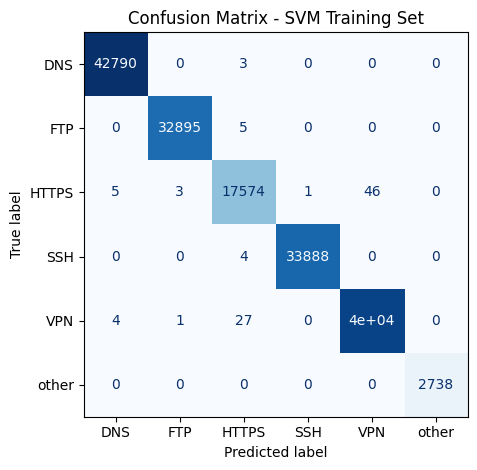


SVM - TEST PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       1.00      1.00      1.00      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      1.00      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Testing Metrics:
Accuracy  : 0.9993
Precision : 0.9993
Recall    : 0.9993
F1 Score  : 0.9993
Saved: SVM_Test_Confusion_Matrix.png


<Figure size 800x600 with 0 Axes>

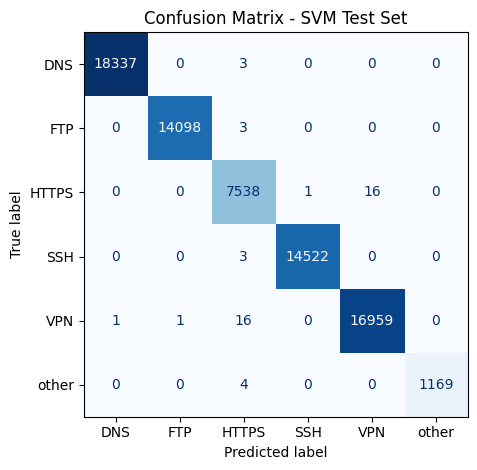


FINAL SVM PERFORMANCE SUMMARY
    Dataset  Accuracy  Precision    Recall  F1 Score
0  Training  0.999416   0.999416  0.999416  0.999416
1   Testing  0.999339   0.999340  0.999339  0.999340

SVM_model.pkl and SVM_features.pkl saved successfully!


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

import joblib



# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])

merged_df = merged_df.replace(
    [np.inf, -np.inf],
    np.nan
)


X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])

y = merged_df["Label"]





# =========================================================
# 2. OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)


X_imputed = SimpleImputer(
    strategy="mean"
).fit_transform(X)


mask = iso.fit_predict(X_imputed) == 1


X = X[mask]

y = y[mask]


print(f"Remaining samples after outlier removal: {len(X)}")





# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.3,

    stratify=y,

    random_state=42
)





# =========================================================
# 4. SVM PIPELINE
# =========================================================

svm_pipeline = Pipeline([


    ("imputer", SimpleImputer(strategy="mean")),


    ("select", SelectKBest(
        score_func=f_classif,
        k=20
    )),


    ("scaler", StandardScaler()),



    ("svm", SVC(

        kernel="rbf",

        C=1.0,

        gamma="scale",

        probability=True,

        random_state=42

    ))

])





# =========================================================
# 5. TRAIN SVM MODEL
# =========================================================

print("\nTraining SVM Model...")

svm_pipeline.fit(
    X_train,
    y_train
)





# =========================================================
# 6. TRAINING PREDICTION
# =========================================================

y_train_pred = svm_pipeline.predict(
    X_train
)





# =========================================================
# 7. TRAINING PERFORMANCE
# =========================================================

print("\n===================================")
print("SVM - TRAINING PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)


train_precision = precision_score(
    y_train,
    y_train_pred,
    average="weighted"
)


train_recall = recall_score(
    y_train,
    y_train_pred,
    average="weighted"
)


train_f1 = f1_score(
    y_train,
    y_train_pred,
    average="weighted"
)



print("Training Metrics:")

print(f"Accuracy  : {train_accuracy:.4f}")

print(f"Precision : {train_precision:.4f}")

print(f"Recall    : {train_recall:.4f}")

print(f"F1 Score  : {train_f1:.4f}")





# Training Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(

    y_train,

    y_train_pred,

    display_labels=label_encoder.classes_.astype(str),

    cmap="Blues",

    colorbar=False

)


plt.title("Confusion Matrix - SVM Training Set")

plt.tight_layout()

plt.show()






# =========================================================
# 8. TEST PREDICTION
# =========================================================

y_test_pred = svm_pipeline.predict(
    X_test
)





# =========================================================
# 9. TEST PERFORMANCE
# =========================================================

print("\n===================================")
print("SVM - TEST PERFORMANCE")
print("===================================")



print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)




test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)


test_precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)


test_recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)


test_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)




print("Testing Metrics:")

print(f"Accuracy  : {test_accuracy:.4f}")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")







# Test Confusion Matrix

plt.figure(figsize=(8,6))


ConfusionMatrixDisplay.from_predictions(

    y_test,

    y_test_pred,

    display_labels=label_encoder.classes_.astype(str),

    cmap="Blues",

    colorbar=False

)


plt.title("Confusion Matrix - SVM Test Set")

plt.tight_layout()

plt.savefig(
    "SVM_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: SVM_Test_Confusion_Matrix.png")

plt.show()




# =========================================================
# 10. FINAL PERFORMANCE SUMMARY
# =========================================================

results = pd.DataFrame({

    "Dataset":[
        "Training",
        "Testing"
    ],


    "Accuracy":[
        train_accuracy,
        test_accuracy
    ],


    "Precision":[
        train_precision,
        test_precision
    ],


    "Recall":[
        train_recall,
        test_recall
    ],


    "F1 Score":[
        train_f1,
        test_f1
    ]

})


print("\nFINAL SVM PERFORMANCE SUMMARY")

print(results)






# =========================================================
# 11. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(
    svm_pipeline,
    "SVM_model.pkl"
)



# Save selected feature names

imputer = svm_pipeline.named_steps["imputer"]

selector = svm_pipeline.named_steps["select"]


feature_names = imputer.get_feature_names_out()


selected_features = feature_names[
    selector.get_support()
]


joblib.dump(
    selected_features.tolist(),
    "SVM_features.pkl"
)


print("\nSVM_model.pkl and SVM_features.pkl saved successfully!")

In [32]:
from sklearn.ensemble import VotingClassifier


# --- Hybrid Pipeline ---
hybrid_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),  # needed for KNN & MLP
    ("ensemble", VotingClassifier(
        estimators=[
            ("rf", rf_pipeline),
            ("knn", knn_pipeline),
            ("logreg", logreg_pipeline),
            ("xgb", xgb_pipeline),
            ("svm", svm_pipeline)
            
        ],
        voting="soft",   # probability averaging
        weights=[1, 1, 1, 1, 1],  # 25% each
        n_jobs=-1
    ))
])

print("\nRunning HYBRID Ensemble (25% each)...")
hybrid_pipeline.fit(X_train, y_train)

# =========================================================
# 🔎 TEST EVALUATION
# =========================================================

y_test_pred_hybrid = hybrid_pipeline.predict(X_test)

print("\nHYBRID MODEL – TEST SET PERFORMANCE")
print(classification_report(
    y_test,
    y_test_pred_hybrid,
    target_names=label_encoder.classes_.astype(str)
))

print("Hybrid Accuracy:", accuracy_score(y_test, y_test_pred_hybrid))


# =========================================================
# SAVE HYBRID MODEL
# =========================================================

joblib.dump(hybrid_pipeline, "Hybrid_model.pkl")
print("Saved Hybrid_model.pkl")



Running HYBRID Ensemble (25% each)...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=20 is greater than n_features=10. All the features will be returned.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



HYBRID MODEL – TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18340
         FTP       1.00      1.00      1.00     14101
       HTTPS       1.00      1.00      1.00      7555
         SSH       1.00      1.00      1.00     14525
         VPN       1.00      1.00      1.00     16977
       other       1.00      1.00      1.00      1173

    accuracy                           1.00     72671
   macro avg       1.00      1.00      1.00     72671
weighted avg       1.00      1.00      1.00     72671

Hybrid Accuracy: 0.9995321379917711
Saved Hybrid_model.pkl


In [33]:
import pandas as pd
import joblib
import numpy as np
import collections

# ======================
# Paths
# ======================
model_path = 'Hybrid_model.pkl'

# ======================
# Load artifacts
# ======================
try:
    model = joblib.load(model_path)
    #label_encoder = joblib.load(label_encoder_path)
    print(" Model and label encoder loaded")
except Exception as e:
    raise RuntimeError(f"Artifact loading failed: {e}")


training_features = list(model.named_steps['imputer'].feature_names_in_) # Convert to list for DataFrame indexing

print(f"Features expected by the pipeline: {training_features}")
print(f"Count: {len(training_features)}")

# ======================
# Load test data
# ======================
test1_csv = 'testcsv.csv'
df_test = pd.read_csv(test1_csv, low_memory=False)
df_test.rename(columns=COLUMN_MAPPING, inplace=True)
print(" Test data (df_203) loaded")

# The pipeline will then perform imputation, feature selection, and scaling internally.
X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)


# The pipeline will handle imputation, feature selection, and scaling internally.
predictions = model.predict(X_test)

# Decode labels
decoded_predictions = label_encoder.inverse_transform(predictions)

# ======================
# Results
# ======================
print("\n Predictions completed")
print("Total samples:", len(decoded_predictions))

print("\nPrediction label distribution:")
for label, count in collections.Counter(decoded_predictions).items():
    print(f"{label}: {count}")

print("\nFirst 20 predictions:")
print(decoded_predictions)

 Model and label encoder loaded
Features expected by the pipeline: ['flow_byts_s', 'flow_pkts_s', 'tot_fwd_pkts', 'tot_bwd_pkts', 'totlen_fwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'pkt_len_max', 'fwd_header_len', 'flow_iat_mean', 'flow_iat_max', 'fwd_iat_min', 'bwd_iat_mean', 'bwd_urg_flags', 'fin_flag_cnt', 'syn_flag_cnt', 'down_up_ratio', 'active_max', 'active_mean', 'active_std', 'idle_min', 'bwd_byts_b_avg', 'fwd_seg_size_avg', 'bwd_seg_size_avg', 'subflow_bwd_pkts', 'subflow_fwd_byts']
Count: 29


FileNotFoundError: [Errno 2] No such file or directory: 'testcsv.csv'

In [ ]:
import pandas as pd
import numpy as np
import joblib
import collections

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# ======================
# Paths
# ======================
MODEL_PATH = 'Hybrid_model.pkl'
TEST_CSV_PATH = 'testcsv.csv'
OUTPUT_CSV_PATH = 'testcsv_with_predictions.csv'
CONF_MATRIX_CSV = 'confusion_matrix.csv'

# ======================
# Load model
# ======================
try:
    model = joblib.load(MODEL_PATH)
    print(" Model loaded successfully")
except Exception as e:
    raise RuntimeError(f"Model loading failed: {e}")

# ======================
# Load test data
# ======================
df_test = pd.read_csv(TEST_CSV_PATH, low_memory=False)
print(" Test CSV loaded")

if 'Label' not in df_test.columns:
    raise ValueError("Column 'Label' not found in test CSV")

# ======================
# Recreate LabelEncoder
# ======================
label_encoder = LabelEncoder()

# Fit on TRUE labels (strings)
df_test['Label_encoded'] = label_encoder.fit_transform(df_test['Label'])

print("\n Label classes:")
for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

# ======================
# Get expected features
# ======================
training_features = list(
    model.named_steps['imputer'].feature_names_in_
)

print(f"\nFeatures expected by model: {len(training_features)}")

# ======================
# Feature alignment
# ======================
missing_features = set(training_features) - set(df_test.columns)
if missing_features:
    raise ValueError(f"Missing features in test data: {missing_features}")

X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)

# ======================
# Predict
# ======================
pred_encoded = model.predict(X_test)

# Decode predictions back to string labels
pred_labels = label_encoder.inverse_transform(pred_encoded)

# ======================
# Add predictions to dataframe
# ======================
df_test['Predicted_Label'] = pred_labels

# Move Predicted_Label next to Label
label_idx = df_test.columns.get_loc('Label')
cols = list(df_test.columns)
cols.insert(label_idx + 1, cols.pop(cols.index('Predicted_Label')))
df_test = df_test[cols]

# ======================
# Save CSV
# ======================
df_test.to_csv(OUTPUT_CSV_PATH, index=False)
print(f"\n Predictions saved to {OUTPUT_CSV_PATH}")

# ======================
# Evaluation
# ======================
y_true = df_test['Label_encoded']
y_pred = pred_encoded

# Accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"\n Accuracy: {accuracy:.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

print("\n Confusion Matrix:")
print(cm_df)

# Save confusion matrix
cm_df.to_csv(CONF_MATRIX_CSV)
print(f" Confusion matrix saved to {CONF_MATRIX_CSV}")

# Classification report
print("\n Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_
))

# ======================
# Prediction distribution
# ======================
print("\n Prediction label distribution:")
for label, count in collections.Counter(pred_labels).items():
    print(f"{label}: {count}")

print("\n Done")


In [ ]:
pip freeze

In [ ]:
import pandas as pd
import joblib
import numpy as np
import collections
from sklearn.metrics import confusion_matrix, accuracy_score

# ======================
# Paths
# ======================
model_path = 'RF_model.pkl'

# ======================
# Load artifacts
# ======================
try:
    model = joblib.load(model_path)
    print("Model loaded")
except Exception as e:
    raise RuntimeError(f"Artifact loading failed: {e}")

# Extract features expected by the model
training_features = list(model.named_steps['imputer'].feature_names_in_)  # Convert to list for DataFrame indexing
print(f"Features expected by the pipeline: {training_features}")
print(f"Count: {len(training_features)}")

# ======================
# Load test data
# ======================
test1_csv = 'testcsv.csv'
df_test = pd.read_csv(test1_csv, low_memory=False)
df_test.rename(columns=COLUMN_MAPPING, inplace=True)
print("Test data loaded")

# Prepare test data for prediction
X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)

# Make predictions using the model
predictions = model.predict(X_test)

# Decode labels (if label_encoder is used)
# decoded_predictions = label_encoder.inverse_transform(predictions)

# For now, assuming you are not using label encoding, you can directly use predictions.
# Store predictions in the DataFrame as a new column "predict_label"
df_test['predict_label'] = predictions

# Save the DataFrame with predictions to a CSV file
output_csv = 'predictions_output.csv'
df_test.to_csv(output_csv, index=False)
print(f"Predictions saved to {output_csv}")

# ======================
# Results
# ======================
# Print prediction label distribution
print("\nPrediction label distribution:")
for label, count in collections.Counter(predictions).items():
    print(f"{label}: {count}")

# First 20 predictions
print("\nFirst 20 predictions:")
print(predictions[:20])

# ======================
# Confusion Matrix and Accuracy
# ======================
# Assuming you have the true labels, you can compare predictions to the actual labels.
# Replace 'Label' with the actual column name containing true labels in your test data.

true_labels = df_test['Label']  # Replace with the actual column name

# Convert true_labels and predictions to be of the same type (both numeric or both strings)
# If predictions are numeric, convert true_labels to numeric as well:
true_labels = pd.to_numeric(true_labels, errors='coerce')  # This converts to numeric and coerces errors to NaN

# Remove rows where true_labels is NaN (invalid labels)
df_test = df_test.dropna(subset=['Label'])  # Drop rows with NaN in 'Label' column
true_labels = df_test['Label']  # Update true_labels after dropping rows

# Generate confusion matrix
cm = confusion_matrix(true_labels, predictions)
print("\nConfusion Matrix:")
print(cm)

# Compute accuracy
accuracy = accuracy_score(true_labels, predictions)
print(f"\nAccuracy: {accuracy:.4f}")
